In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.io_utils import ler_acc

In [2]:
def get_matriz_acc(arquivo, list_janelas):
    g = list_janelas[list_janelas["arquivo"] == arquivo]
    sinal = ler_acc(arquivo)
    matriz = []
    for _, row in g.iterrows():
        matriz.append(sinal[row["ini"]:row["fim"]])
    return np.array(matriz)

In [3]:
list_janelas = pd.read_csv("../data/processed/janelas.csv")
print("janelas:", len(list_janelas), "registros")
reg = list_janelas.iloc[0]
sinal = ler_acc(reg["arquivo"])
recorte = sinal[reg["ini"] : reg["fim"]]
print(f"tamanho: {len(recorte)}")

janelas: 2370 registros
tamanho: 20000


In [4]:
w = get_matriz_acc(reg["arquivo"], list_janelas)

media = w.mean(axis=1)
desvio = w.std(axis=1)
pot = (w ** 2).mean(axis=1)
rms = np.sqrt(pot)
pico_abs = np.abs(w).max(axis=1)
pico_pico = w.max(axis=1) - w.min(axis=1)
crista = pico_abs / rms

print(w.shape, rms.shape)
print(rms[0], crista[0], media[0], desvio[0])
print(np.allclose(pot, media ** 2 + desvio ** 2))
print(crista.min() >= 1)

(30, 20000) (30,)
0.04444642259028861 5.332383895092937 -0.0009012549928156659 0.04443728412619792
True
True


In [5]:
linhas = []
for arquivo in list_janelas["arquivo"].unique():
    g = list_janelas[list_janelas["arquivo"] == arquivo].reset_index(drop=True)
    w = get_matriz_acc(arquivo, list_janelas)

    media = w.mean(axis=1)
    desvio = w.std(axis=1)
    pot = (w ** 2).mean(axis=1)
    rms = np.sqrt(pot)
    pico_abs = np.abs(w).max(axis=1)
    pico_pico = w.max(axis=1) - w.min(axis=1)
    crista = pico_abs / rms

    parte = g[["arquivo", "id", "rotulo", "F", "SV", "SP", "C", "jan"]].copy()
    parte["media"] = media
    parte["desvio"] = desvio
    parte["potencia"] = pot
    parte["rms"] = rms
    parte["pico_abs"] = pico_abs
    parte["pico_a_pico"] = pico_pico
    parte["crista"] = crista
    linhas.append(parte)

feat_t = pd.concat(linhas, ignore_index=True)

assert len(feat_t) == len(list_janelas)
assert feat_t.isna().sum().sum() == 0
assert np.allclose(feat_t["potencia"], feat_t["media"] ** 2 + feat_t["desvio"] ** 2)
assert (feat_t["crista"] >= 1).all()
print(feat_t.groupby("rotulo").size())

feat_t.to_csv("../data/processed/features_tempo.csv", index=False)
print(feat_t.groupby("rotulo")[["media", "rms", "desvio", "pico_abs", "pico_a_pico", "crista"]].agg(["mean", "std"]).round(4).T.to_string())

rotulo
defeituoso    1890
saudavel       480
dtype: int64
rotulo            defeituoso  saudavel
media       mean     -0.0013   -0.0009
            std       0.0008    0.0006
rms         mean      0.1260    0.1141
            std       0.1154    0.0905
desvio      mean      0.1260    0.1141
            std       0.1154    0.0905
pico_abs    mean      0.5324    0.4794
            std       0.4205    0.3490
pico_a_pico mean      0.9976    0.8908
            std       0.8075    0.6598
crista      mean      4.8558    4.6886
            std       1.0195    1.0298


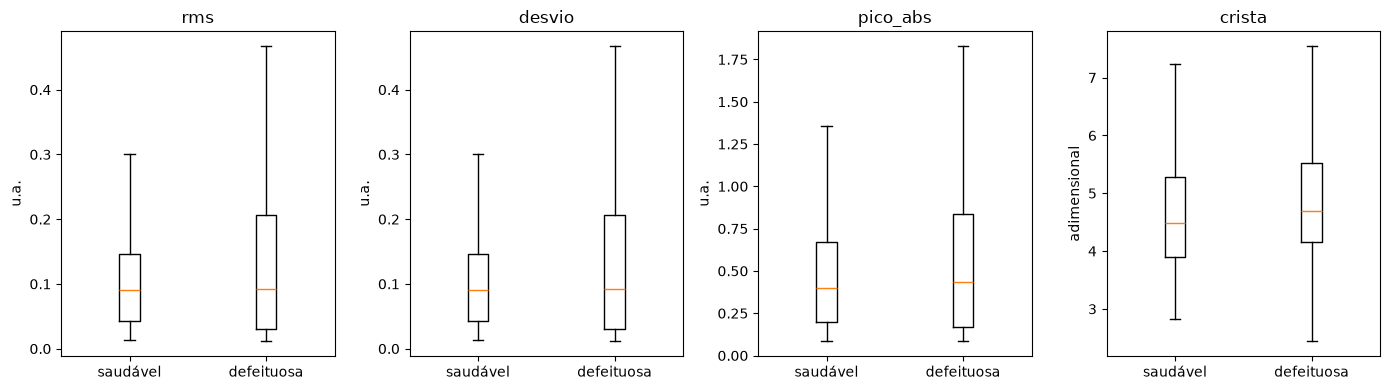

In [6]:
cols = ["rms", "desvio", "pico_abs", "crista"]
fig, axs = plt.subplots(1, 4, figsize=(14, 4))
for ax, c in zip(axs, cols):
    dados = [feat_t.loc[feat_t["rotulo"] == g, c] for g in ["saudavel", "defeituoso"]]
    ax.boxplot(dados, tick_labels=["saudável", "defeituosa"], showfliers=False)
    ax.set_title(c)
    ax.set_ylabel("u.a." if c != "crista" else "adimensional")
plt.tight_layout()
plt.savefig("../results/figures/boxplots_tempo.png", dpi=150)
plt.show()

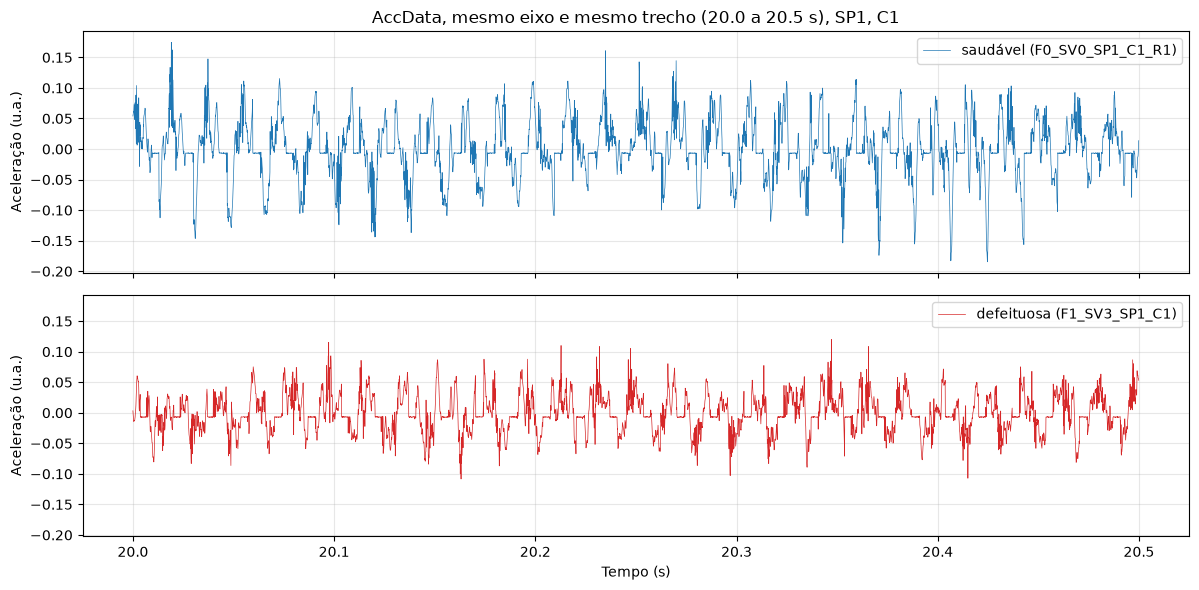

In [10]:
fs = 10000
T0, T1 = 20.0, 20.5
ARQ = {"saudavel": "F0_SV0_SP1_C1_R1.mat", "defeituoso": "F1_SV3_SP1_C1.mat"}
ROT = {"saudavel": "saudável", "defeituoso": "defeituosa"}
CORES = {"saudavel": "tab:blue", "defeituoso": "tab:red"}

i0, i1 = int(T0 * fs), int(T1 * fs)
t = np.arange(i0, i1) / fs

fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, (cond, nome) in zip(axs, ARQ.items()):
    x = ler_acc(nome)[i0:i1]
    assert len(x) == len(t)
    ax.plot(t, x, lw=0.5, color=CORES[cond], label=f"{ROT[cond]} ({nome[:-4]})")
    ax.set_ylabel("Aceleração (u.a.)")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

axs[0].set_title(f"AccData, mesmo eixo e mesmo trecho ({T0:.1f} a {T1:.1f} s), SP1, C1")
axs[-1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.savefig("../results/figures/sinais_tempo_par.png", dpi=150)
plt.show()